# 19. 시기 변화에 대한 강건성 — 시간순 분할에서 raw PVC, D4 규칙, 결합
학습: 2022~2023년 14일(912타점, 불량 22)의 **날짜별 개수만**. 시험: 2024-02-06~03-13 5일(931타점, 불량 51). 2024-01-31은 시험 차체와 겹쳐 제외한다(04와 같은 분할).
raw PVC는 학습 14일로 10시드 학습 후 시험일 점수. D4는 학습이 없어 날짜마다 그대로 계산. 결합 = 날짜 안 순위 평균. 숨긴 정답으로 시험일 포착을 채점한다.
날짜 하나 빼기(LODO)는 미래 날짜도 학습에 쓰므로 낙관적일 수 있다. 이 분할이 현장 사용(과거로 학습 → 새 날 추천)에 더 가깝다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.metrics import roc_auc_score
import br
from br import spec as S, budget as B, plot as P
from wl.metrics import inclusion_prob
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
X, day, cnt, y, _ = S.load_polito()
Xd, *_ = S.load_polito("derived5_absz")
body = wldata.load_polito().body.values
TR = np.array([d_ < "2024" for d_ in day]); TE = np.array([d_ >= "2024-02-01" for d_ in day])
assert not set(body[TR]) & set(body[TE])
print("학습", TR.sum(), "타점, 불량", y[TR].sum(), "| 시험", TE.sum(), "타점, 불량", y[TE].sum())
ub, bag = np.unique(day[TR], return_inverse=True)
c_tr = cnt.loc[ub].values.astype(int)
raw_s = np.mean([S.fit_score("PVC MLP", X, bag, c_tr, TR, TE, s)[0] for s in range(10)], 0)
ae_s = np.mean([S.fit_score("AE (정답 미사용)", X, bag, c_tr, TR, TE, s)[0] for s in range(5)], 0)
d4_s = Xd.sum(axis=1).values[TE]
yt, dt, bt = y[TE], day[TE], body[TE]
rk = lambda s: pd.Series(s).groupby(dt).rank(pct=True).values
comb = (rk(raw_s) + rk(d4_s)) / 2
ud, gi = np.unique(dt, return_inverse=True); n = np.bincount(gi); pos = np.bincount(gi, weights=yt)
rng = np.random.default_rng(10); ubt = np.unique(bt)
Wb = np.stack([np.bincount(d_, minlength=len(ubt)) for d_ in rng.integers(0, len(ubt), (5000, len(ubt)))])[:, np.searchsorted(ubt, bt)]
def ci(a): return f"{np.mean(a):+.3f} [{np.quantile(a,.025):+.3f}, {np.quantile(a,.975):+.3f}]"

학습 912 타점, 불량 22 | 시험 931 타점, 불량 51


In [2]:
S_ = {"raw PVC": raw_s, "D4 규칙": d4_s, "결합": comb, "AE": ae_s}
rows = []
for b in (.05, .1, .2, .3):
    k = np.ceil(b * n - 1e-9); pr = (k / n)[gi]
    r = {"예산": f"{int(b*100)}%", "검사 수": int(k.sum()), "무작위": round((pr * yt).sum(), 1)}
    P_ = {nm: inclusion_prob(s, k, gi) for nm, s in S_.items()}
    for nm, p_ in P_.items():
        r[nm] = round((p_ * yt).sum(), 1)
    for nm in ["raw PVC", "D4 규칙", "결합"]:
        r[f"{nm}−무작위 [95%]"] = ci((Wb @ ((P_[nm] - pr) * yt)) / (Wb @ yt))
    r["결합−raw [95%]"] = ci((Wb @ ((P_["결합"] - P_["raw PVC"]) * yt)) / (Wb @ yt))
    rows.append(r)
tt = pd.DataFrame(rows); tt.to_csv(br.RES / "temporal_check.csv", index=False, encoding="utf-8-sig")
print(f"시험 불량 {int(yt.sum())}개 중 포착 수"); display(tt)
print("AUROC:", {nm: round(roc_auc_score(yt, s), 3) for nm, s in S_.items()})

시험 불량 51개 중 포착 수


,예산,검사 수,무작위,raw PVC,D4 규칙,결합,AE,raw PVC−무작위 [95%],D4 규칙−무작위 [95%],결합−무작위 [95%],결합−raw [95%]
0,5%,49,3.4,4.0,9.0,9.0,3.0,"+0.011 [-0.032, +0.051]","+0.112 [+0.065, +0.173]","+0.106 [+0.013, +0.182]","+0.095 [+0.000, +0.177]"
1,10%,95,5.7,10.0,14.0,17.0,7.0,"+0.081 [-0.027, +0.184]","+0.162 [+0.094, +0.216]","+0.219 [+0.081, +0.348]","+0.138 [+0.018, +0.284]"
2,20%,188,10.3,21.0,19.0,21.0,9.0,"+0.206 [+0.089, +0.298]","+0.171 [+0.058, +0.298]","+0.206 [+0.085, +0.299]","+0.001 [-0.073, +0.081]"
3,30%,281,15.8,24.0,29.0,25.0,11.0,"+0.154 [+0.031, +0.237]","+0.257 [+0.088, +0.397]","+0.177 [+0.050, +0.297]","+0.023 [-0.067, +0.143]"


AUROC: {'raw PVC': 0.583, 'D4 규칙': 0.709, '결합': 0.686, 'AE': 0.458}


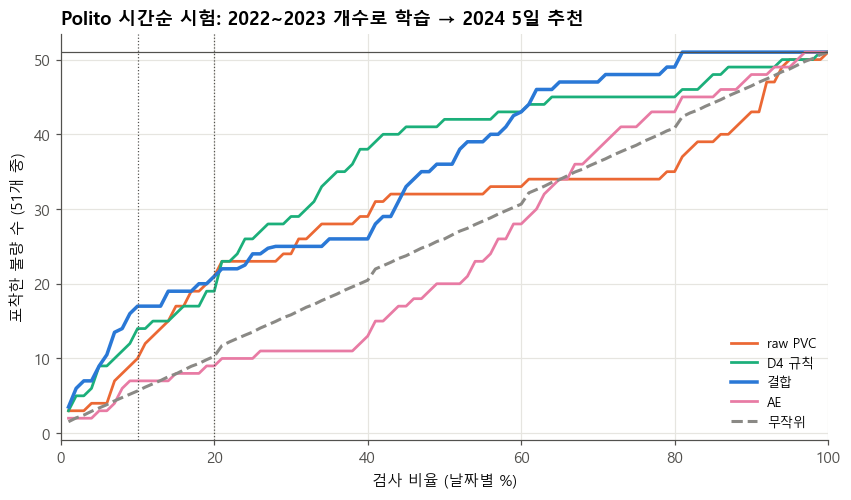

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
bb = B.BUDGETS
for nm, col in [("raw PVC", P.PAL[1]), ("D4 규칙", P.PAL[2]), ("결합", P.PAL[0]), ("AE", P.PAL[4])]:
    ax.plot(bb * 100, [(inclusion_prob(S_[nm], np.ceil(b * n - 1e-9), gi) * yt).sum() for b in bb], color=col, lw=2.3 if nm == "결합" else 1.8, label=nm)
ax.plot(bb * 100, [(np.ceil(b * n - 1e-9) / n * pos).sum() for b in bb], "--", color=P.GRAY, label="무작위")
ax.axhline(yt.sum(), color=P.INK2, lw=.8)
for b in (10, 20): ax.axvline(b, color=P.INK2, lw=.8, ls=":")
ax.set_xlim(0, 100); ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel(f"포착한 불량 수 ({int(yt.sum())}개 중)")
ax.set_title("Stellantis N.V. 시간순 시험: 2022~2023 개수로 학습 → 2024 5일 추천", loc="left", fontweight="bold"); ax.legend(fontsize=8.5, loc="lower right")
P.save(fig, "17_temporal_check"); plt.show()